# Primer zadatka iz oblasti neuronskih mreža

In [1]:
# Import potrebnih modula /  klasa i funkcija
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

In [2]:
# Učitavamo podatke (navodimo koje vrednosti ćemo smatrati nedostajućim: '-', ' ', '')
df = pd.read_csv("data/breast_cancer.csv", na_values=['-', ' ', ''])

display(df.head())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              567 non-null    float64
 1   mean texture             567 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [3]:
# Proveravamo da li varijable imaju nedostajuće vrednosti
print(df.isna().sum())
# Varijable mean radius i mean texture imaju po 2 nedostajuće vrednosti

mean radius                2
mean texture               2
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
isBenign                   0
dtype: int64


Varijable `mean radius` i `mean texture` su numeričkog tipa i imaju mali broj nedostajućih vrednosti. Zbog toga ćemo koristiti metod zamene prosečnom vrednošću (`mean` i `median`). Da bismo odlučili da li da koristimo mean ili median, prvo ćemo proveriti raspodelu ovih varijabli pomoću Shapiro-Wilk testa. Ako varijable imaju normalnu raspodelu, nedostajuće vrednosti ćemo zameniti mean-om, a ako nemaju normalnu raspodelu, koristićemo median.

In [4]:
# Proveravamo da li varijable imaju normalnu raspodelu
p_radius = shapiro(df['mean radius'].dropna())[1]
p_texture = shapiro(df['mean texture'].dropna())[1]

print("p-vrednost za mean radius:", p_radius)
print("p-vrednost za mean texture:", p_texture)

# Obe varijable imaju vrednost p < 0.05 što znači da nemaju normalnu raspodelu i nedostajuće vrednosti zamenićemo medijanom

median_radius = df['mean radius'].median()
print(median_radius)
median_texture = df['mean texture'].median()
print(median_texture)
# Dobili smo da su medijane 13.37 i 18.87 za mean radius i mean texture respektivno

# Zamena nedostajućih vrednosti medijanama
df['mean radius'] = df['mean radius'].fillna(median_radius)
df['mean texture'] = df['mean texture'].fillna(median_texture)

print(df.isna().sum())
# Nema više nedostajućih vrednosti

p-vrednost za mean radius: 3.792843427944636e-14
p-vrednost za mean texture: 9.007535733256736e-08
13.37
18.87
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
isBenign           

In [6]:
# Delimo podatke na trening (80%) i test (20%) skup

X = df.drop(columns='isBenign')
y = df['isBenign']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [1]:
p_r = shapiro(df['mean radius'].dropna())[1]
p_t = shapiro(df['mean texture'].dropna())[1]

med_r = df['mean radius'].median()
med_t = df['mean texture'].median()

df['mean radius'] = df['mean radius'].fillna(med_r)
df['mean texture'] = df['mean texture'].fillna(med_t)


X_train= df.frop(columns='isBenign')
y_test = df['isBenign']

X_train , X_test , y_train,y_test  = train_test_split(X,y,test_size=0.2,random_state = 42 , stratify=y)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(64,32),max_iter=1000,random_state=42,solver='sgd')
mlp.fit(X_train, y_train)
y_predict = mlp.predict(X_test)

plt.figure(figsize=(10,10))
plt.plot(mlp.loss_curve_)
plt.xlabel('Iteracija')
plt.ylabel('Loss')
plt.show()


cm = confusion_matrix(y_test,y_predict)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['malignant','benign'])
disp.plot()
plt.grid()
plt.show()

def metrics(y_true,y_pred):
    accuracy = accuracy_score(y_test, y_predict)
    precision = precision_score(y_test,y_predict, pos_label=0)
    recall = recall_score(y_test,y_predict,posl_lable=0)
    f1 = f1_score(y_test,y_predict,pos_label=0)
    return{
        'accuracy':accuracy,
        'precision':precision,
        'recall':recall,
        'f1':f1
    }

NameError: name 'df' is not defined

In [ ]:
# Standardizujemo varijable
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [8]:
# Kreiranje neuronske mreže
mlp1=MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=42, solver='sgd')

In [ ]:
mlp2 = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=42, solver='sgd')

Arhitektura kreirane neuronske mreže je **30–64–32–1**.

- Ulazni sloj sadrži **30 neurona**.
- Mreža ima **dva skrivena sloja**:
    - prvi skriveni sloj sadrži **64 neurona**,
    - drugi skriveni sloj sadrži **32 neurona**.
- Izlazni sloj sadrži **1 neuron**.

In [9]:
# Trening neuronske mreže
mlp1.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


In [ ]:
mlp2.fit(X_train, y_train)

Tokom treninga neuronske mreže izvršavaju se sledeći koraci:

1. **Forward propagation** - ulazni podaci prolaze kroz mrežu i izračunava se predikcija modela.

2. **Računanje greške (loss)** - predikcije modela porede se sa stvarnim vrednostima i izračunava se greška modela.

3. **Backward propagation** - na osnovu izračunate greške određuje se kako svaki parametar mreže utiče na grešku.

4. **Ažuriranje parametara** - težine i bias vrednosti mreže ažuriraju se pomoću optimizacionog algoritma sa ciljem smanjenja greške modela.

Ovaj proces se ponavlja kroz više epoha, pri čemu jedna epoha predstavlja jedan prolazak kroz ceo trening skup podataka.

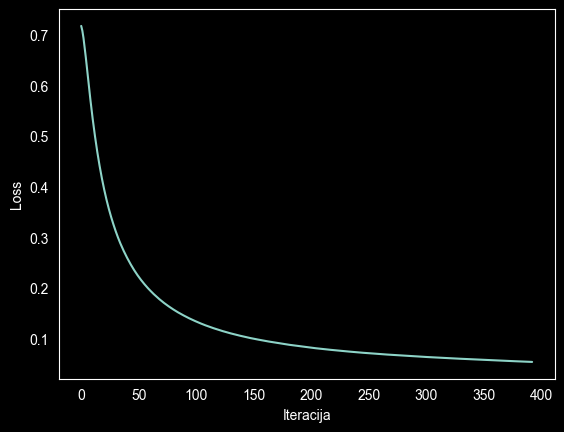

In [12]:
# Prikaz promene vrednosti funkcije greške tokom treninga
plt.figure()
plt.plot(mlp1.loss_curve_)

plt.xlabel("Iteracija")
plt.ylabel("Loss")
plt.grid()
plt.show()

In [13]:
y_pred=mlp1.predict(X_test)

In [ ]:
y_prediction = mlp2.predict(X_test)

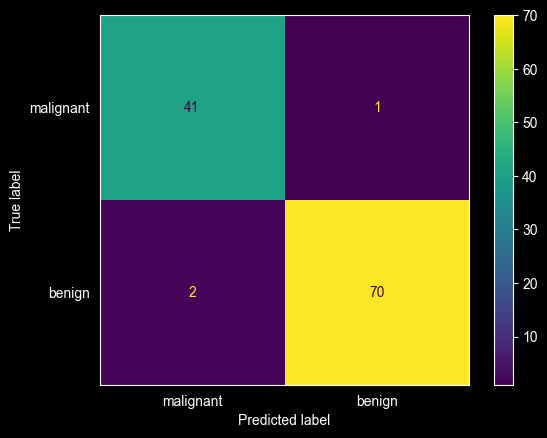

In [15]:
# Kreiranje matrice konfuzije
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['malignant','benign'])
disp.plot()
plt.grid()
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['malignant','benign'])
disp.plot()
plt.show()

#### Interpretacija matrice konfuzije

- **True positive (TP)** – za 41 tumor smo predvideli da će bit maligni i one zaista jeste bio maligni
- **True negative (TN)** – za 70 tumora smo predvideli da će biti benigni i oni zaista jesu bili benigni
- **False positive (FP)** – za 2 tumora smo predvideli da će biti maligni, a oni su zapravo bili benigni
- **False negative (FN)** – za 1 tumor smo predvideli da će biti benigni, a on je zapravo bio maligni

Na glavnoj dijagonali matrice (41 i 70) nalaze se tačne predikcije, dok se na sporednoj dijagonali (2 i 1) nalaze pogrešne predikcije.

#### Evaluacione metrike

4 metrike koje se najčešće koriste za procenu uspešnosti klasifikatora su:

- **Accuracy (tačnost)** – procenat tačnih predikcija (i pozitivnih i negativnih) u odnosu na sve observacije
- **Precision (preciznost)** – procenat observacija za koje smo predvideli da su pozitivne i koje zaista jesu pozitivne
- **Recall (odziv)** – procenat observacija koje su stvarno pozitivne i koje smo mi tačno predvideli kao pozitivne
- **F1 score** – mera za balansiranje vrednosti precision-a i recall-a

In [16]:
def compute_eval_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=0)
    recall = recall_score(y_true, y_pred, pos_label=0)
    f1 = f1_score(y_true, y_pred, pos_label=0)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [ ]:
def metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=0)
    recall = recall_score(y_true, y_pred, pos_label=0)
    f1 = f1_score(y_true, y_pred, pos_label=0)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [ ]:
mlp2_eval = metrics(y_test, y_pred)
print(mlp2_eval)

In [17]:
# Izračunavanje vrednosti evaluacionih metrika
mlp1_eval=compute_eval_metrics(y_test, y_pred)
print(mlp1_eval)

{'accuracy': 0.9736842105263158, 'precision': 0.9534883720930233, 'recall': 0.9761904761904762, 'f1': 0.9647058823529412}
